In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.style.use("ggplot")

In [3]:

df = pd.read_csv(
    "ShortenDataSet.csv",)


In [4]:
df

,LABEL,TEXT
0,ham,Your opinion about me? 1. Over 2. Jada 3. Kusr...
1,ham,What's up? Do you want me to come online? If y...
2,ham,So u workin overtime nigpun?
3,ham,"Also sir, i sent you an email about how to log..."
4,Smishing,Please Stay At Home. To encourage the notion o...
...,...,...
5966,ham,:( but your not here....
5967,ham,Becoz its &lt;#&gt; jan whn al the post ofic...
5968,ham,Its a valentine game. . . send dis msg to all ...
5969,ham,We r outside already.


In [5]:
df.shape

(5971, 2)

In [6]:
df.dtypes

LABEL    str
TEXT     str
dtype: object

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5971 entries, 0 to 5970
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   LABEL   5971 non-null   str  
 1   TEXT    5971 non-null   str  
dtypes: str(2)
memory usage: 93.4 KB


In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum() / df.shape[0] * 100

#precentage of how many are duplicated

np.float64(1.4737899849271479)

In [10]:
df.drop_duplicates(inplace=True)

In [11]:
df

,LABEL,TEXT
0,ham,Your opinion about me? 1. Over 2. Jada 3. Kusr...
1,ham,What's up? Do you want me to come online? If y...
2,ham,So u workin overtime nigpun?
3,ham,"Also sir, i sent you an email about how to log..."
4,Smishing,Please Stay At Home. To encourage the notion o...
...,...,...
5965,ham,I'm in class. Did you get my text.
5966,ham,:( but your not here....
5967,ham,Becoz its &lt;#&gt; jan whn al the post ofic...
5968,ham,Its a valentine game. . . send dis msg to all ...


In [12]:
df["LABEL"].value_counts()

LABEL
ham         4834
Smishing     551
spam         453
Spam          23
smishing      22
Name: count, dtype: int64

In [13]:
df["LABEL"].value_counts(normalize=True)*100

LABEL
ham         82.168961
Smishing     9.365970
spam         7.700153
Spam         0.390957
smishing     0.373959
Name: proportion, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

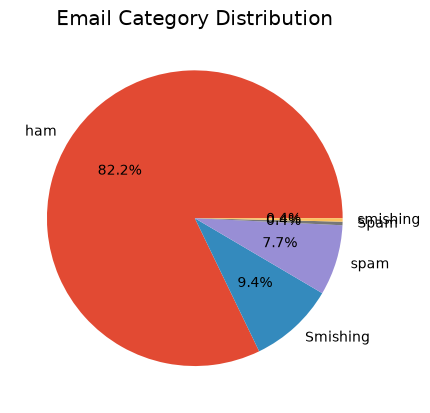

In [14]:

df["LABEL"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")
plt.title("Email Category Distribution")
plt.show


In [15]:
df["LABEL"] = df["LABEL"].map({
    "ham" :0,
    "Smishing" : 1,
    "smishing" : 1,
    "spam" : 2,
    "Spam" : 2
    
})

In [16]:
df.head()

,LABEL,TEXT
0,0,Your opinion about me? 1. Over 2. Jada 3. Kusr...
1,0,What's up? Do you want me to come online? If y...
2,0,So u workin overtime nigpun?
3,0,"Also sir, i sent you an email about how to log..."
4,1,Please Stay At Home. To encourage the notion o...


In [17]:
import warnings
warnings.filterwarnings("ignore")

In [18]:
import sklearn
from sklearn.model_selection import train_test_split

In [19]:
X= df["TEXT"]

In [20]:
y= df["LABEL"]

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify= y
)

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

tf = TfidfVectorizer(
    stop_words= "english",
    max_features= 5000,
    ngram_range= (1,2)
)

In [23]:
X_train_tf = tf.fit_transform(X_train)

In [24]:
X_test_tf = tf.transform(X_test)

In [25]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV


In [26]:
models = {
    "Navie Bayes": (
        MultinomialNB(),
        {
            "alpha" : [0.1, 0.5, 1, 2, 5]
        }
    ), 
    "LogisticRegression" : (
        LogisticRegression(
            class_weight= "balanced",
            max_iter= 1000
        ),
        {
            "C" : [0.01, 0.1, 1, 10, 100]
        }
    ),
    "Linear SWM": (
        LinearSVC(
            class_weight="balanced"
        ),
        {
            "C" : [0.01, 0.1, 1, 10, 10]
        }
        
    ), 
    "Random Forest": (
        RandomForestClassifier(
            class_weight="balanced"
        ),
        {
            "n_estimators" : [100, 200, 300],
            "max_depth" : [10, 20, None],
            "min_samples_split" : [2, 5, 10]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced"
        ),
        {
         "max_depth" : [10, 20, None],
         "min_samples_split" : [2, 5, 10]
        }
    ),

    "Gradient Boosting" : (
        GradientBoostingClassifier(),
        {
             "n_estimators" : [100, 200],
             "learning_rate" : [0.01, 0.05, 0.1 ],
             "max_depth": [3,5]
        }
    ),
     "KNN": (
         KNeighborsClassifier(),
         {
            "n_neighbors": [3,5,7,9] 
         }
     )

}

In [27]:
result = [ ]

best_models = {}

for name, (model, params) in models.items():

    search = RandomizedSearchCV(
        estimator= model,
        param_distributions= params,
        n_iter= 10,
        cv = 5,
        scoring="f1_weighted",
        n_jobs= -1
    )

    search.fit(X_train_tf,y_train)

    best_model = search.best_estimator_

    best_models[name] = best_model

    predictions = best_model.predict(X_test_tf)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average="weighted")
    recall = recall_score(y_test, predictions, average="weighted")
    f1 = f1_score(y_test, predictions, average="weighted")

    try:
        probabilities = best_model.predict_proba(X_test_tf)
        auc = roc_auc_score(
            y_test,
            probabilities,
            multi_class="ovr",
            average="weighted",
            labels=best_model.classes_
    )
    except (ValueError, AttributeError):
        auc = np.nan

    result.append({
        "Model" : name,
        "Accuracy" : accuracy,
        "Precision" : precision,
        "Recall" : recall,
        "F1 Score" : f1,
        "ROC AUC" : auc,
        "Best Params" : search.best_params_

    })
        
    

    


In [28]:
result_df= pd.DataFrame(result)

result_df = result_df.sort_values(
    by = ["F1 Score", "ROC AUC"],
    ascending= False
)

In [29]:
result_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
3,Random Forest,0.955820,0.954016,0.955820,0.954746,0.988028,"{'n_estimators': 200, 'min_samples_split': 10,..."
1,LogisticRegression,0.954970,0.952975,0.954970,0.953624,0.988757,{'C': 10}
2,Linear SWM,0.955820,0.953306,0.955820,0.953090,NaN,{'C': 1}
0,Navie Bayes,0.955820,0.952726,0.955820,0.953032,0.984068,{'alpha': 0.1}
5,Gradient Boosting,0.936279,0.929776,0.936279,0.929374,0.975607,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
4,Decision Tree,0.915888,0.912604,0.915888,0.913678,0.892385,"{'min_samples_split': 5, 'max_depth': None}"
6,KNN,0.898895,0.890022,0.898895,0.873960,0.843451,{'n_neighbors': 3}


In [30]:
result_df.style.background_gradient(
    cmap= "Greens",
    subset= ["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
3,Random Forest,0.955820,0.954016,0.955820,0.954746,0.988028,"{'n_estimators': 200, 'min_samples_split': 10, 'max_depth': None}"
1,LogisticRegression,0.954970,0.952975,0.954970,0.953624,0.988757,{'C': 10}
2,Linear SWM,0.955820,0.953306,0.955820,0.953090,nan,{'C': 1}
0,Navie Bayes,0.955820,0.952726,0.955820,0.953032,0.984068,{'alpha': 0.1}
5,Gradient Boosting,0.936279,0.929776,0.936279,0.929374,0.975607,"{'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}"
4,Decision Tree,0.915888,0.912604,0.915888,0.913678,0.892385,"{'min_samples_split': 5, 'max_depth': None}"
6,KNN,0.898895,0.890022,0.898895,0.873960,0.843451,{'n_neighbors': 3}


In [31]:
result_df.reset_index(inplace=True)

In [32]:
result_df.drop(columns= "index", inplace=True)

In [33]:
result_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Best Params
0,Random Forest,0.955820,0.954016,0.955820,0.954746,0.988028,"{'n_estimators': 200, 'min_samples_split': 10,..."
1,LogisticRegression,0.954970,0.952975,0.954970,0.953624,0.988757,{'C': 10}
2,Linear SWM,0.955820,0.953306,0.955820,0.953090,NaN,{'C': 1}
3,Navie Bayes,0.955820,0.952726,0.955820,0.953032,0.984068,{'alpha': 0.1}
4,Gradient Boosting,0.936279,0.929776,0.936279,0.929374,0.975607,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
5,Decision Tree,0.915888,0.912604,0.915888,0.913678,0.892385,"{'min_samples_split': 5, 'max_depth': None}"
6,KNN,0.898895,0.890022,0.898895,0.873960,0.843451,{'n_neighbors': 3}


In [34]:
best_model_name = result_df.iloc[0]["Model"]

In [35]:
best_model_name

'Random Forest'

In [36]:
best_model = best_models[best_model_name]

In [37]:
best_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first f

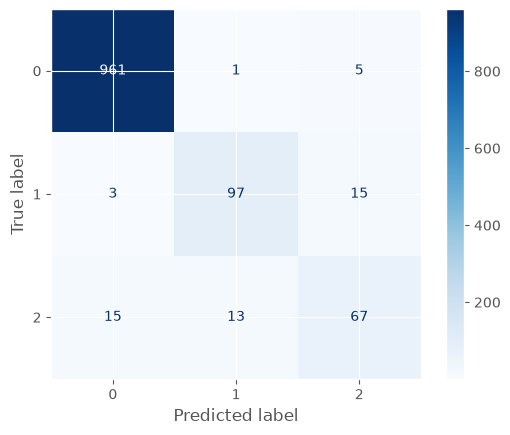

In [38]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
 best_model,
 X_test_tf,
 y_test,
 cmap = "Blues"
)

In [39]:
texts = [
    "Hey are how you!",
    "Congratulations! You won a free iPhone. Click here now.",
    "Just a reminder, we have a meeting tomorrow",
    "URGENT! Claim your $1000 Walmart gift card today!",
   "Hello from Orange. For 1 month's free access to games, news and sport, plus 10 free texts and 20 photo messages, reply YES. Terms apply: www.orange.co.uk/ow"

]

texts_vectorized = tf.transform(texts)

predictionsTwo = best_model.predict(texts_vectorized)

for i in range(len(texts)):
    prediction = predictionsTwo[i]

    label = "They are phishing or scamming! (scam)" if prediction == 2 else \
            "They are phishing or scamming! (smishing)" if prediction == 1 else \
            "This is fine! (ham)"

    print(label, ":", texts[i])


This is fine! (ham) : Hey are how you!
They are phishing or scamming! (smishing) : Congratulations! You won a free iPhone. Click here now.
This is fine! (ham) : Just a reminder, we have a meeting tomorrow
They are phishing or scamming! (smishing) : URGENT! Claim your $1000 Walmart gift card today!
They are phishing or scamming! (scam) : Hello from Orange. For 1 month's free access to games, news and sport, plus 10 free texts and 20 photo messages, reply YES. Terms apply: www.orange.co.uk/ow


In [40]:
import pickle

with open("spam_detector_model.pkl","wb" ) as file:
    pickle.dump(best_model, file)

In [41]:
with open ("tf_vectorizer2.pkl", "wb") as file:
    pickle.dump(tf, file)

print("Woohoo! It's done!")

Woohoo! It's done!
